In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tahirmehmood0/lahore-house-listings-from-zameen-com-2025/lahore_house_listings_zameen.csv


# **Understand Data**

In [7]:
import pandas as pd 
df= pd.read_csv('/kaggle/input/datasets/tahirmehmood0/lahore-house-listings-from-zameen-com-2025/lahore_house_listings_zameen.csv')

In [8]:
df.shape

(18249, 23)

In [9]:
df.head()

,Title,Location,Type,Price,Area,Bedrooms,Bathrooms,Purpose,Date Posted,Built Year,...,Furnished,Gym,Study Room,Drawing Room,Dining Room,Lawn/Garden,Swimming Pool,Electricity Backup,Lounge/Sitting Room,Link
0,ACTUALLY 25 MARLA DOUBLE UNIT LUXURIOUS & GRAC...,"DHA Phase 6 - Block F, DHA Phase 6, DHA Defenc...",House,8.15 Crore,1 Kanal,6,7,For Sale,2025-07-27,2024.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_phase_6_dh...
1,3 Years Installment Plan Luxury Brand New Hous...,"Park View City, Lahore, Punjab",House,1.5 Crore,5 Marla,4,5,For Sale,2025-07-25,2012.0,...,True,False,False,True,True,True,False,True,True,https://www.zameen.com/Property/lahore_park_vi...
2,5 Marla Luxury House In Rose Block Of Park-Vie...,"Park View City - Rose Block, Park View City, L...",House,2.4 Crore,5 Marla,4,4,For Sale,2025-07-25,2025.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/park_view_city...
3,Full Basement 1 kanal Brand New Luxury House N...,"DHA Phase 7 - Block S, DHA Phase 7, DHA Defenc...",House,7.5 Crore,1 Kanal,5,6,For Sale,2025-07-25,2024.0,...,False,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_phase_7_dh...
4,1 Kanal Dream Home With Private Pool In DHA Ph...,"DHA Phase 6, DHA Defence, Lahore, Punjab",House,6.95 Crore,1 Kanal,6,7,For Sale,2025-07-25,2024.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_defence_dh...


In [10]:
df.dtypes

Title                   object
Location                object
Type                    object
Price                   object
Area                    object
Bedrooms                object
Bathrooms               object
Purpose                 object
Date Posted             object
Built Year             float64
Kitchens                 int64
Store Rooms              int64
Servant Quarters         int64
Furnished                 bool
Gym                       bool
Study Room                bool
Drawing Room              bool
Dining Room               bool
Lawn/Garden               bool
Swimming Pool             bool
Electricity Backup        bool
Lounge/Sitting Room       bool
Link                    object
dtype: object

In [11]:
df.isnull().sum()

Title                     0
Location                  0
Type                      0
Price                     0
Area                      0
Bedrooms                  0
Bathrooms                 0
Purpose                   0
Date Posted            6930
Built Year             4752
Kitchens                  0
Store Rooms               0
Servant Quarters          0
Furnished                 0
Gym                       0
Study Room                0
Drawing Room              0
Dining Room               0
Lawn/Garden               0
Swimming Pool             0
Electricity Backup        0
Lounge/Sitting Room       0
Link                      0
dtype: int64

In [12]:
df.columns

Index(['Title', 'Location', 'Type', 'Price', 'Area', 'Bedrooms', 'Bathrooms',
       'Purpose', 'Date Posted', 'Built Year', 'Kitchens', 'Store Rooms',
       'Servant Quarters', 'Furnished', 'Gym', 'Study Room', 'Drawing Room',
       'Dining Room', 'Lawn/Garden', 'Swimming Pool', 'Electricity Backup',
       'Lounge/Sitting Room', 'Link'],
      dtype='object')

# **Data Quality Check**

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Title                18249 non-null  object 
 1   Location             18249 non-null  object 
 2   Type                 18249 non-null  object 
 3   Price                18249 non-null  object 
 4   Area                 18249 non-null  object 
 5   Bedrooms             18249 non-null  object 
 6   Bathrooms            18249 non-null  object 
 7   Purpose              18249 non-null  object 
 8   Date Posted          11319 non-null  object 
 9   Built Year           13497 non-null  float64
 10  Kitchens             18249 non-null  int64  
 11  Store Rooms          18249 non-null  int64  
 12  Servant Quarters     18249 non-null  int64  
 13  Furnished            18249 non-null  bool   
 14  Gym                  18249 non-null  bool   
 15  Study Room           18249 non-null 

In [15]:
df.describe()

,Built Year,Kitchens,Store Rooms,Servant Quarters
count,13497.000000,18249.000000,18249.000000,18249.000000
mean,2022.673631,1.679489,0.793742,0.856704
std,4.933459,1.057279,0.784329,1.244107
min,1960.000000,0.000000,0.000000,0.000000
25%,2023.000000,1.000000,0.000000,0.000000
50%,2024.000000,2.000000,1.000000,1.000000
75%,2025.000000,2.000000,1.000000,1.000000
max,2121.000000,32.000000,22.000000,111.000000


In [16]:
for col in df.select_dtypes(include='object').columns:
    print("\nColumn:", col)
    print(df[col].unique()[:20])


Column: Title
['ACTUALLY 25 MARLA DOUBLE UNIT LUXURIOUS & GRACEFUL HOUSE AVAILABLE FOR SALE'
 '3 Years Installment Plan Luxury Brand New House In Park View City Lahore'
 '5 Marla Luxury House In Rose Block Of Park-View City Is Up For SALE At Best Price'
 'Full Basement 1 kanal Brand New Luxury House Nearby DHA Raya in S Block Phase 7 DHA Lahore'
 '1 Kanal Dream Home With Private Pool In DHA Phase 6 A True Showstopper'
 '3 Years Installments Plan 5 Marla Brand New House For Sale In Park View City'
 'Ultra Modern - 10 Marla Brand New House - Prime Location - Valencia Town'
 '01 KANAL MODREN HOUSE ON 150 FEET MAIN ROAD DHA PHASE 6'
 'Prime Location 2 Kanal House For sale In DHA Phase 2 - Block R Lahore'
 'Prime Location House Is Available For sale In Eden Boulevard Housing Scheme'
 '5 Marla Beautiful House For Sale In Eastern Housing Society Lahore Near Head Office'
 '5 Marla Good Condition Carefully Used House For Sale in JJ Block Phase 4 DHA Lahore'
 'Brand New - Modern Designer House 

In [17]:
#The minimum Built Year
print('min built year=' ,df['Built Year'].min())

#The maximum Built Year
print('max buit year=' ,df['Built Year'].max())

#The most common Built Year
print('most com=', df['Built Year'].mode())

min built year= 1960.0
max buit year= 2121.0
most com= 0    2025.0
Name: Built Year, dtype: float64


In [18]:
print('median built year=', df['Built Year'].median())

median built year= 2024.0


In [19]:
df[df['Built Year'] > 2026]['Built Year'].value_counts()

Built Year
2028.0    21
2027.0    20
2029.0     7
2058.0     3
2055.0     1
2121.0     1
Name: count, dtype: int64

In [20]:
df[df['Built Year'] > 2026].index

Index([  568,   613,  1284,  1480,  1892,  2197,  2256,  2447,  2658,  2862,
        2954,  3788,  3951,  4054,  4814,  5091,  5658,  5822,  6681,  7009,
        7130,  7540,  8020,  8086,  8215,  8287,  9223,  9348,  9816, 10035,
       10278, 10454, 10645, 10801, 11621, 11832, 11858, 11930, 11951, 11967,
       12278, 12520, 12625, 12787, 13000, 13123, 14415, 14807, 16221, 16596,
       16604, 17662, 18031],
      dtype='int64')

In [21]:
df.loc[df['Built Year'] > 2026, ['Built Year']]

,Built Year
568,2028.0
613,2029.0
1284,2028.0
1480,2027.0
1892,2027.0
2197,2028.0
2256,2029.0
2447,2027.0
2658,2029.0
2862,2027.0


# **Data Cleaning**

In [22]:
import numpy as np

In [23]:
df.loc[df['Built Year'] > 2026, ['Built Year']]= np.nan

In [24]:
df['Built Year'].isnull().sum()

np.int64(4805)

In [25]:
df['Built Year']=df['Built Year'].fillna(df['Built Year']).median()

In [26]:
df['Built Year'].isnull().sum()

np.int64(0)

# **Understand the Target: Price**

In [27]:
print("Minimum:", df['Price'].min())
print("Maximum:", df['Price'].max())


Minimum: 1 Arab
Maximum: 99 Lakh


In [28]:
df['Price'].head(20)

0     8.15 Crore
1      1.5 Crore
2      2.4 Crore
3      7.5 Crore
4     6.95 Crore
5      1.5 Crore
6     4.95 Crore
7       14 Crore
8     16.5 Crore
9        2 Crore
10     2.1 Crore
11    2.79 Crore
12    6.25 Crore
13     5.6 Crore
14     1.5 Crore
15    2.25 Crore
16      11 Crore
17    3.35 Crore
18     5.4 Crore
19    5.11 Crore
Name: Price, dtype: object

In [29]:
df['Price_Number'] = df['Price'].str.split().str[0]

In [30]:
df['Price_Number'] = pd.to_numeric(df['Price_Number'])

In [31]:
df['unit_price'] = df['Price'].str.split().str[1]

In [32]:
df[['Price', 'Price_Number','unit_price' ]]

,Price,Price_Number,unit_price
0,8.15 Crore,8.15,Crore
1,1.5 Crore,1.50,Crore
2,2.4 Crore,2.40,Crore
3,7.5 Crore,7.50,Crore
4,6.95 Crore,6.95,Crore
...,...,...,...
18244,1.15 Crore,1.15,Crore
18245,1.15 Crore,1.15,Crore
18246,1.1 Crore,1.10,Crore
18247,1.1 Crore,1.10,Crore


In [33]:
conversion = {
    'Lakh': 1,
    'Crore': 100,
    'Arab': 10000
}

In [34]:
df['Price_Lakh'] = df['Price_Number'] * df['unit_price'].map(conversion)

In [35]:
df[['Price', 'Price_Lakh']].head()

,Price,Price_Lakh
0,8.15 Crore,815.0
1,1.5 Crore,150.0
2,2.4 Crore,240.0
3,7.5 Crore,750.0
4,6.95 Crore,695.0


In [36]:
print("Minimum:", df['Price_Lakh'].min())
print("Maximum:", df['Price_Lakh'].max())
print("Average:", df['Price_Lakh'].mean())
print("Median:", df['Price_Lakh'].median())

Minimum: 14.9
Maximum: 20000.0
Average: 585.831784246012
Median: 355.0


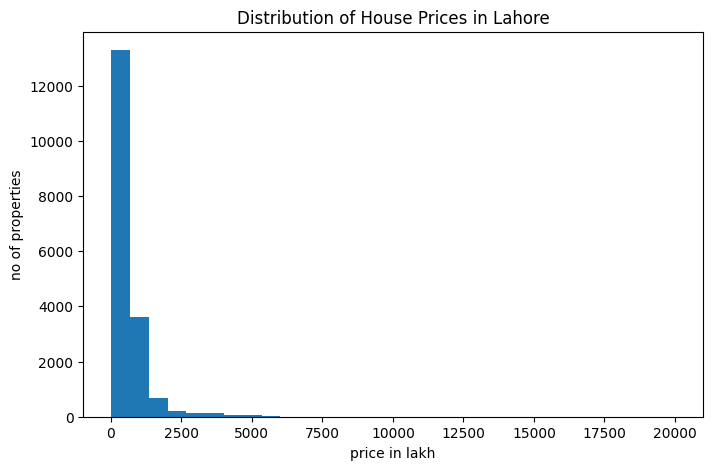

In [37]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(df['Price_Lakh'], bins=30)

plt.xlabel('price in lakh')
plt.ylabel('no of properties')
plt.title('Distribution of House Prices in Lahore')

plt.show()

# **Analyze Property Area**

In [38]:
df['Area'].value_counts().head(20)

Area
5 Marla      4992
1 Kanal      4516
10 Marla     3716
3 Marla      1043
2 Kanal       763
8 Marla       442
4 Marla       400
7 Marla       251
12 Marla      226
6 Marla       199
2 Marla       172
3.5 Marla     151
2.5 Marla     150
1.2 Kanal     101
11 Marla       88
9 Marla        77
1.1 Kanal      73
15 Marla       63
14 Marla       62
4 Kanal        52
Name: count, dtype: int64

In [39]:
df['area_number'] = df['Area'].str.split().str[0]

In [40]:
df['area_number']= pd.to_numeric(df['area_number'])

In [41]:
df['area_number'].dtypes

dtype('float64')

In [42]:
df[['Area', 'area_number']]

,Area,area_number
0,1 Kanal,1.0
1,5 Marla,5.0
2,5 Marla,5.0
3,1 Kanal,1.0
4,1 Kanal,1.0
...,...,...
18244,3.5 Marla,3.5
18245,3.5 Marla,3.5
18246,3.5 Marla,3.5
18247,3.5 Marla,3.5


In [43]:
df['area'] = df['Area'].str.split().str[1]

In [44]:
df[['Area','area_number','area']]

,Area,area_number,area
0,1 Kanal,1.0,Kanal
1,5 Marla,5.0,Marla
2,5 Marla,5.0,Marla
3,1 Kanal,1.0,Kanal
4,1 Kanal,1.0,Kanal
...,...,...,...
18244,3.5 Marla,3.5,Marla
18245,3.5 Marla,3.5,Marla
18246,3.5 Marla,3.5,Marla
18247,3.5 Marla,3.5,Marla


In [45]:
conversion = {
    'Marla': 1,
    'Kanal': 20
}

df['Area_Marla'] = df['area_number'] * df['area'].map(conversion)

In [46]:
df['Area_Marla']

0        20.0
1         5.0
2         5.0
3        20.0
4        20.0
         ... 
18244     3.5
18245     3.5
18246     3.5
18247     3.5
18248     5.0
Name: Area_Marla, Length: 18249, dtype: float64

In [47]:
area_price_corr = df['Area_Marla'].corr(df['Price_Lakh'])
print(area_price_corr)

0.7999779175499859


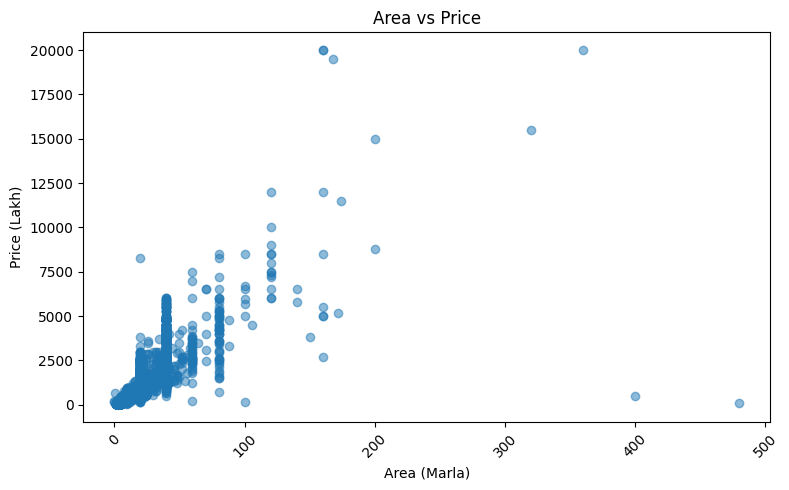

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Area_Marla'], df['Price_Lakh'], alpha=0.5)

plt.xlabel('Area (Marla)')
plt.ylabel('Price (Lakh)')
plt.title('Area vs Price')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# **Price Prediction**

In [49]:
y = df['Price_Lakh']

In [50]:
X = df[['Area_Marla', 'Bedrooms', 'Bathrooms', 'Built Year']]

In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [52]:
df[['Area_Marla', 'Bedrooms', 'Bathrooms', 'Built Year']].isin(['-']).sum()

Area_Marla      0
Bedrooms      318
Bathrooms     420
Built Year      0
dtype: int64

In [53]:
df['Bedrooms'] = df['Bedrooms'].replace('-', np.nan)
df['Bathrooms'] = df['Bathrooms'].replace('-', np.nan)

df['Bedrooms'] = pd.to_numeric(df['Bedrooms'])
df['Bathrooms'] = pd.to_numeric(df['Bathrooms'])

df['Bedrooms'] = df['Bedrooms'].fillna(df['Bedrooms'].median())
df['Bathrooms'] = df['Bathrooms'].fillna(df['Bathrooms'].median())

In [54]:
print(df[['Bedrooms', 'Bathrooms']].isnull().sum())

Bedrooms     0
Bathrooms    0
dtype: int64


In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [56]:
import numpy as np
import pandas as pd

features = ['Area_Marla', 'Bedrooms', 'Bathrooms', 'Built Year']

# Replace '-' with missing values
df[features] = df[features].replace('-', np.nan)

# Convert everything to numbers
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill missing values with median
for col in features:
    df[col] = df[col].fillna(df[col].median())

In [57]:
X = df[features]
y = df['Price_Lakh']

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [59]:
df['Price_Lakh'].isnull().sum()

np.int64(6)

In [60]:
df = df.dropna(subset=['Price_Lakh'])

In [61]:
from sklearn.linear_model import LinearRegression

In [62]:
X = df[['Area_Marla', 'Bedrooms', 'Bathrooms', 'Built Year']]
y = df['Price_Lakh']

X_train, X_test, y_train, LR_y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

LR_y_pred = model.predict(X_test)


In [63]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(LR_y_test, LR_y_pred)
rmse = np.sqrt(mean_squared_error(LR_y_test, LR_y_pred))
r2 = r2_score(LR_y_test, LR_y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 181.09332703056504
RMSE: 385.4058147000907
R²: 0.7361267051478269


In [64]:
new_house = pd.DataFrame({
    'Area_Marla': [12],
    'Bedrooms': [4],
    'Bathrooms': [3],
    'Built Year': [2022]
})

predicted_price = model.predict(new_house)

print("Predicted Price:", predicted_price[0], "Lakh")

Predicted Price: 519.5962112873086 Lakh


In [65]:
print(df[['Location', 'Type', 'Purpose']].isnull().sum())

Location    0
Type        0
Purpose     0
dtype: int64


In [66]:
df['Date Posted'] = pd.to_datetime(
    df['Date Posted'],
    errors='coerce'
)

In [67]:
df['Posted Year'] = df['Date Posted'].dt.year

In [68]:
df['Posted Year'] = df['Posted Year'].fillna(
    df['Posted Year'].median()
)

In [69]:
X = df[
    [
        'Area_Marla',
        'Bedrooms',
        'Bathrooms',
        'Built Year',
        'Location',
        'Type',
        'Purpose',
        'Posted Year'
    ]
]

y = df['Price_Lakh']

In [70]:
X = pd.get_dummies(
    X,
    columns=['Location', 'Type', 'Purpose'],
    drop_first=True
)

In [71]:
print(X.isnull().sum().sum())
print(y.isnull().sum())

0
0


In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [73]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [74]:
y_pred = model.predict(X_test)

In [75]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MAE = mean_absolute_error(y_test, y_pred)
RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
R2 = r2_score(y_test, y_pred)

print("MAE:", MAE)
print("RMSE:", RMSE)
print("R²:", R2)

MAE: 180.09431309925824
RMSE: 394.61324528264464
R²: 0.7233681180481708


In [76]:
from sklearn.ensemble import RandomForestRegressor

In [77]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [78]:
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [79]:
rf_pred = rf_model.predict(X_test)

In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²:", rf_r2)

Random Forest MAE: 120.09060930540356
Random Forest RMSE: 329.68734331690706
Random Forest R²: 0.8069083630073639


# **Prediction** 

In [81]:
results = pd.DataFrame({
    'Actual Price': LR_y_test,
    'Predicted Price': LR_y_pred
})

print(results.head(40))

       Actual Price  Predicted Price
217           700.0       959.773948
12469          95.0        65.056627
15089         365.0       509.061258
5058          160.0       157.317056
8892          335.0       509.061258
563           115.0        88.121734
6954          130.0       102.538084
14342         220.0       217.863620
14268         710.0      1020.320512
9129          290.0       157.317056
16107         190.0       207.274165
3502          525.0       448.514693
8596           87.0         8.336957
11611         330.0       555.191472
424           445.0       448.514693
1162          180.0       217.863620
5857          525.0      1154.884262
16957         425.0       498.471802
16977         670.0      1170.191838
3128          690.0       661.868251
12652         185.0       157.317056
4502          325.0       509.061258
5426          210.0       274.583291
9666          675.0       970.363404
1704          205.0       157.317056
290           750.0       970.363404
8

In [82]:
results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

print(results.head(40))

       Actual Price  Predicted Price
217           700.0      1017.108688
12469          95.0        30.805976
15089         365.0       412.268837
5058          160.0        82.850765
8892          335.0       390.362542
563           115.0        41.343723
6954          130.0        84.593636
14342         220.0       188.718378
14268         710.0      1184.546568
9129          290.0       228.517450
16107         190.0       105.086464
3502          525.0       629.895880
8596           87.0        97.833552
11611         330.0       183.106768
424           445.0       501.687203
1162          180.0       165.697223
5857          525.0       533.750000
16957         425.0       389.748543
16977         670.0      1233.181589
3128          690.0       610.557337
12652         185.0       167.040928
4502          325.0       394.605880
5426          210.0       151.536357
9666          675.0       769.350565
1704          205.0       228.517450
290           750.0       477.150757
8